# Chapter 4 — Sampling: averages without enumeration

Chapter 3 computed every average by brute force: list every labeling, weigh it, add up. That worked because our boards were tiny. The coin model on a $2\times2$ torus has $2^8=256$ labelings. On a $4\times4$ torus it has $2^{32}$, about four billion. On a four-dimensional grid with 8 vertices per side it has $2^{16384}$, a number with almost five thousand digits.

Yet a single average such as "how calm is a typical face?" is just *one number*. Pollsters estimate what millions of people think by asking a thousand of them. This chapter does the same for models: we learn to **draw random labelings** from a model and average over the draws. At the end, the method finds something we did not put in: in four dimensions, the coin model makes a sudden jump at a very particular stiffness.

**What you'll learn**

- Why averages over random samples work, and how to put an error bar on them.
- How to build a Markov chain whose long-run behavior is exactly a given model, using only *local* information.
- How to tell when a chain has run long enough, and how fast array code makes it.

**Prerequisites:** chapters 2 and 3 (models, averages, invariants). From probability, we use Markov chains and their stationary distributions.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from lgt import *
from lgt import viz
from lgt.grid import GridModel

viz.use_style()
rng = np.random.default_rng(4)

**Helpers for this chapter.** `mean_face` is the invariant we will estimate throughout: the average over faces of $\chi(U_f)$. For the coin model it equals $1-2\times(\text{fraction of faces that are defects})$, so 1 means "all calm" and 0 means "half the faces are defects".

In [2]:
def mean_face(G, board, U):
    """Average over faces of chi(face product). Works on a batch of labelings."""
    return G.chi(face_products(G, board, U)).mean(axis=-1)

def running_mean(x):
    return np.cumsum(x) / np.arange(1, len(x) + 1)

## 4.1 Averages from samples

Fix a model $\mu_\beta$ and an invariant $f:G^E\to\mathbb R$. Suppose we could draw labelings $U_1,U_2,\dots,U_n$ independently from $\mu_\beta$. The **sample average**

$$
\bar f_n=\frac1n\sum_{i=1}^n f(U_i)\in\mathbb R
$$

is a random number. The law of large numbers says $\bar f_n\to\langle f\rangle_\beta$, and the central limit theorem says how fast: the typical error is $\sigma/\sqrt n$, where $\sigma^2$ is the variance of $f$ under the model. **The error does not depend on how many labelings exist.** Four billion or $2^{16384}$, a thousand samples give about three correct digits.

Let's watch it happen where we still know the exact answer: the coin model on the $3\times3$ torus ($2^{18}=262{,}144$ labelings), at $\beta=0.5$. We draw independent samples straight from the exact distribution (cheating, for now) and track the running average.

In [3]:
T3 = Board.grid(3, 3, periodic=True)
M3 = Model(T3, Z2(), beta=0.5)
ex = M3.exact()
f_all = mean_face(Z2(), T3, ex.U)                       # f for every labeling
exact = float(np.sum(ex.p * f_all))
sigma = float(np.sqrt(np.sum(ex.p * (f_all - exact) ** 2)))
draws = f_all[rng.choice(len(ex.p), size=4000, p=ex.p)]  # 4000 independent samples
print(f"exact <mean face> = {exact:.4f},  sigma = {sigma:.3f}")
print(f"sample average of 4000 draws = {draws.mean():.4f}")

exact <mean face> = 0.4638,  sigma = 0.299
sample average of 4000 draws = 0.4597


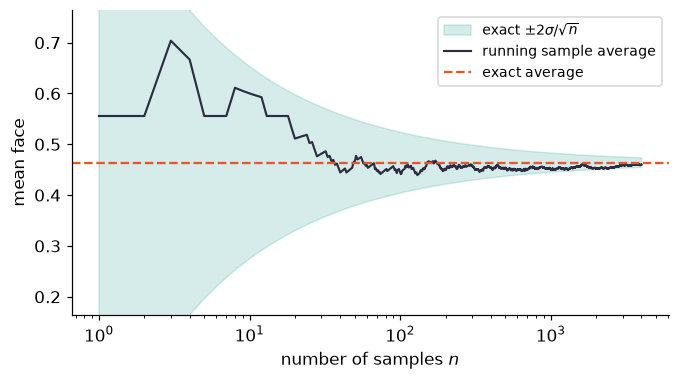

In [4]:
n = np.arange(1, len(draws) + 1)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.fill_between(n, exact - 2 * sigma / np.sqrt(n), exact + 2 * sigma / np.sqrt(n),
                color=viz.TEAL, alpha=0.18, label=r"exact $\pm 2\sigma/\sqrt{n}$")
ax.plot(n, running_mean(draws), color=viz.INK, lw=1.4, label="running sample average")
ax.axhline(exact, color=viz.CORAL, lw=1.5, ls="--", label="exact average")
ax.set(xscale="log", xlabel="number of samples $n$", ylabel="mean face", ylim=(exact - 0.3, exact + 0.3))
ax.legend(loc="upper right", fontsize=9)
plt.show()

The black curve wanders early and then stays inside the shaded funnel, which narrows like $1/\sqrt n$. That funnel is the whole promise of sampling.

> **Recap.** If we can draw independent samples from $\mu_\beta$, the sample average of an invariant converges to $\langle f\rangle_\beta$ with error about $\sigma/\sqrt n$, no matter how many labelings there are.

**Check yourself**

1. How many samples do you need to cut the error by a factor of 10?

<details><summary>Answer</summary>

100 times as many, because the error shrinks like $1/\sqrt n$.

</details>

2. We just drew samples using `ex.p`, the list of all $2^{18}$ probabilities. Why can't we do that on the $4\times4$ torus?

<details><summary>Answer</summary>

Computing those probabilities needs the normalizer $Z$, a sum over all $2^{32}$ labelings, and storing them needs one number per labeling. The next section avoids both.

</details>

## 4.2 A random walk that settles into the model

We cannot draw independent samples without knowing $Z$. But we *can* compare two labelings: the ratio

$$
\frac{\mu_\beta(U')}{\mu_\beta(U)}=e^{-\beta\,(S(U')-S(U))}
$$

needs no $Z$, only the difference in total cost. The idea of **Markov chain Monte Carlo** is to take a random walk on the set of labelings $G^E$, moving from $U$ to $U'$ with probabilities $P(U\to U')$ chosen so that, in the long run, the walk spends a fraction $\mu_\beta(U)$ of its time at each $U$.

> **Fact 4.1 (detailed balance).** If $\mu(U)\,P(U\to U')=\mu(U')\,P(U'\to U)$ for all pairs of labelings, then $\mu$ is a stationary distribution of the chain. If moreover the chain can reach every labeling from every other one, and is not periodic, then the distribution of the walk after $t$ steps converges to $\mu$ from any starting point.

*Why the first part:* sum both sides over $U$. The left side is the probability of being at $U'$ after one step when starting from $\mu$; the right side is $\mu(U')$. The second part is the convergence theorem for finite Markov chains.

**The Metropolis rule.** One step of the walk:

1. pick an edge $e$ (for example, in random order);
2. propose a new label for $e$, drawn uniformly from $G$;
3. compute the change in total cost $\Delta S$;
4. accept the proposal with probability $\min(1,e^{-\beta\Delta S})$; otherwise keep the old label.

Moves that lower the cost are always accepted, and moves that raise it are accepted sometimes. You can check detailed balance in one line: for $\Delta S>0$, $\mu(U)\cdot e^{-\beta\Delta S}=\mu(U')\cdot 1$.

The crucial practical point is that step 3 is cheap.

> **Fact 4.2 (locality).** Changing the label of one edge $e$ changes only the face products of the faces that use $e$. So $\Delta S$ is a sum over those faces alone: 2 faces on a square grid, $2(d-1)$ on a $d$-dimensional grid, no matter how big the board is.

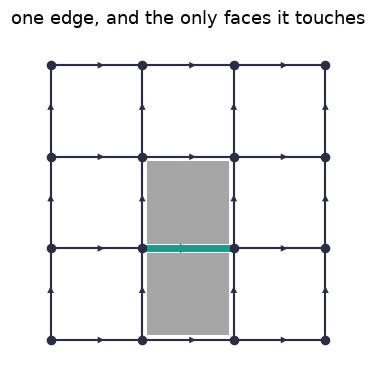

In [5]:
P4 = Board.grid(4, 4)
e = P4.meta["edge_index"][(5, 0)]                      # an interior horizontal edge
touch = [1.0 if e in [e2 for e2, _ in f] else 0.0 for f in P4.faces]
fig, ax = plt.subplots(figsize=(4, 4))
viz.draw_board(ax, P4, face_values=touch, face_cmap="Greys", highlight_walk=[(e, 1)],
               title="one edge, and the only faces it touches")
ax.collections[0].set_alpha(0.35)
plt.show()

The teal edge appears in exactly two faces (shaded). To decide whether to change its label, the walk looks at nothing else.

Let's test the whole recipe against exact enumeration. The library's `Model.metropolis` implements it. On the $2\times2$ torus the exact distribution of the total cost is known, so we compare.

In [6]:
T2 = Board.grid(2, 2, periodic=True)
M2 = Model(T2, Z2(), beta=0.5)
ex2 = M2.exact()
chain = M2.metropolis(rng, n_samples=6000, burn_in=200)
for S in np.unique(ex2.cost):
    exact_p = ex2.p[ex2.cost == S].sum()
    chain_p = np.mean(np.isclose(M2.cost(chain), S))
    print(f"total cost {S:>4.0f}: exact {exact_p:.3f}   Metropolis {chain_p:.3f}")

total cost    0: exact 0.546   Metropolis 0.547
total cost    4: exact 0.444   Metropolis 0.442
total cost    8: exact 0.010   Metropolis 0.011


The frequencies agree to about two decimals, which is what 6000 (correlated) samples can deliver.

> **Recap.** A Markov chain that satisfies detailed balance with respect to $\mu_\beta$ and can reach every labeling eventually samples from $\mu_\beta$. The Metropolis rule achieves this using only cost *differences*, so $Z$ is never needed, and each step only looks at the faces through one edge.

**Check yourself**

1. At $\beta=0$, what does the Metropolis chain do?

<details><summary>Answer</summary>

Every proposal is accepted ($e^{0}=1$), so each visited edge gets a fresh uniform label. After one sweep the labeling is uniform, matching the model at $\beta=0$.

</details>

2. On a 4-dimensional grid, how many faces must be examined to update one edge?

<details><summary>Answer</summary>

$2(d-1)=6$. Each of the 3 other directions gives one face "on each side" of the edge.

</details>

3. Does the chain care that the model is unchanged by reframings?

<details><summary>Answer</summary>

No. It wanders through labelings, including many in the same class, and that is harmless: the class probabilities come out right because the labeling probabilities do. Invariant averages are all we read off.

</details>

## 4.3 Face remainders and the heat bath

For one edge $e$, walk any face $f$ through it starting with $e$ in its stored direction. The face product splits as

$$
U_f=U(e)\,r_f(e),
$$

where the **face remainder** $r_f(e)\in G$ is the product of the face's other labels (glossary 4.8). With everything except $U(e)$ held fixed, the cost of the edge is $\sum_f\varphi\big(U(e)\,r_f(e)\big)$, a function of $U(e)$ alone.

For the coin model this is especially simple. With $\varphi(x)=1-x$, the part of the total cost that involves $e$ is $\text{const}-U(e)\,A(e)$, where

$$
A(e)=\sum_{f\ni e} r_f(e)\in\lbrace -2(d-1),\dots,2(d-1)\rbrace
$$

is the sum of the remainders. So instead of *proposing* and maybe rejecting, we can draw the new label directly from its exact conditional distribution:

$$
\Pr\big(U(e)=+1\mid\text{all other labels}\big)=\frac{e^{\beta A}}{e^{\beta A}+e^{-\beta A}}=\frac{1}{1+e^{-2\beta A}}.
$$

This is the **heat bath** update (statisticians call it Gibbs sampling). The conditional probability is a logistic curve in $A$: the faces around the edge "vote", and $\beta$ sets how much the edge listens.

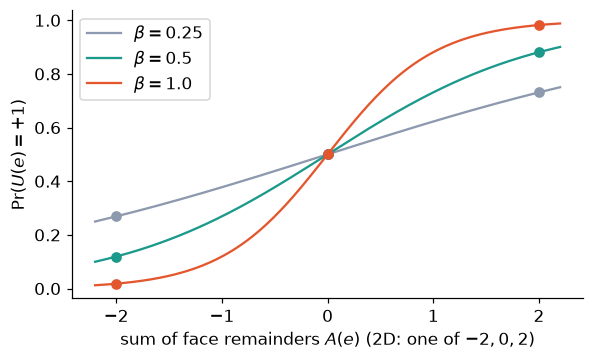

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.4))
A = np.linspace(-2.2, 2.2, 200)
for beta, c in zip([0.25, 0.5, 1.0], [viz.MUTED, viz.TEAL, viz.CORAL]):
    ax.plot(A, 1 / (1 + np.exp(-2 * beta * A)), color=c, label=fr"$\beta={beta}$")
    ax.plot([-2, 0, 2], 1 / (1 + np.exp(-2 * beta * np.array([-2, 0, 2]))), "o", color=c)
ax.set(xlabel="sum of face remainders $A(e)$ (2D: one of $-2,0,2$)",
       ylabel=r"$\Pr(U(e)=+1)$")
ax.legend()
plt.show()

On a square grid $A(e)$ can only be $-2$, $0$ or $2$ (the dots). When both faces "want" $+1$, a stiff model obeys almost surely; when they disagree ($A=0$), the edge flips a fair coin at every stiffness.

A heat-bath sweep on a board takes a few lines. For the coin model inverses are trivial, so a remainder is just the product of the other labels on the face.

In [8]:
def heat_bath_sweep(board, U, beta, rng, faces_of=None):
    faces_of = faces_of or board.faces_of_edge()
    for e in rng.permutation(board.n_edges):
        A = sum(np.prod([U[e2] for e2, _ in board.faces[f] if e2 != e]) for f in faces_of[e])
        U[e] = 1 if rng.random() < 1 / (1 + np.exp(-2 * beta * A)) else -1
    return U

U = random_labeling(Z2(), T2, rng)
vals = [mean_face(Z2(), T2, heat_bath_sweep(T2, U, 0.5, rng)) for _ in range(4000)]
print(f"heat bath: {np.mean(vals[200:]):.4f}   exact: {ex2.average(lambda X: mean_face(Z2(), T2, X)):.4f}")

heat bath: 0.5318   exact: 0.5363


> **Recap.** The face remainder $r_f(e)$ is "the rest of the face" seen from edge $e$. The cost of one edge depends only on the remainders of its faces. For the coin model the conditional distribution of a label is logistic in their sum, and the heat bath samples from it directly.

**Check yourself**

1. On a 3D grid, which values can $A(e)$ take?

<details><summary>Answer</summary>

Each edge lies on $2(d-1)=4$ faces, each remainder is $\pm1$, so $A\in\lbrace -4,-2,0,2,4\rbrace$.

</details>

2. Does a heat-bath update ever "reject"?

<details><summary>Answer</summary>

No. It always draws a new label, but the new label may well equal the old one. Its long-run behavior is the same model; it is often a little more efficient than Metropolis.

</details>

## 4.4 Many edges at once

The Python loop above visits edges one by one. Fact 4.2 suggests something better: **two edges that share no face can be updated at the same time**, because neither one's update depends on the other's label. On a grid we can split the edges into groups of this kind:

- edges pointing in the same direction $\mu$ never share a face if they are not neighbors "sideways";
- so group the direction-$\mu$ edges by the parity (even/odd) of the sum of their *other* coordinates.

That gives $2d$ groups, each updated in one shot with array arithmetic. (On a torus this needs even side lengths, so the parity pattern wraps around consistently.)

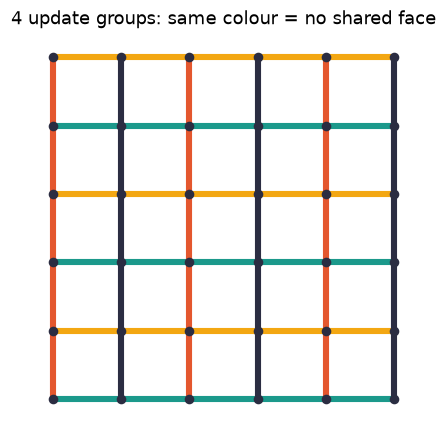

In [9]:
B6 = Board.grid(6, 6)
cols = {(0, 0): viz.TEAL, (0, 1): viz.GOLD, (1, 0): viz.CORAL, (1, 1): viz.INK}
fig, ax = plt.subplots(figsize=(4.6, 4.6))
viz.draw_board(ax, B6, faces=False, show_arrows=False, edge_labels=None)
for (v, mu), e2 in B6.meta["edge_index"].items():
    par = sum(B6.meta["coord"][v][nu] for nu in range(2) if nu != mu) % 2
    (x0, y0), (x1, y1) = B6.pos[B6.edges[e2]]
    ax.plot([x0, x1], [y0, y1], color=cols[(mu, par)], lw=4, solid_capstyle="round", zorder=5)
ax.set_title("4 update groups: same colour = no shared face")
plt.show()

Check any face: its four edges have four different colors. So all teal edges can be redrawn at once, then all gold, and so on.

The library's `GridModel` (in `lgt.grid`) stores a labeling of a $d$-dimensional torus as an array and runs exactly this scheme: heat bath for the coin model, Metropolis for the circle. First, it gives the right answer:

In [10]:
G2 = GridModel((2, 2), Z2(), beta=0.5).hot_start(rng)
G2.sweep(rng, 200)
fast = [(G2.sweep(rng), G2.mean_face())[1] for _ in range(8000)]
print(f"GridModel: {np.mean(fast):.4f}   exact: {ex2.average(lambda X: mean_face(Z2(), T2, X)):.4f}")

GridModel: 0.5384   exact: 0.5363


Second, it is fast. Here is the time per sweep (every edge updated once) on an $8\times8$ torus:

In [11]:
T8 = Board.grid(8, 8, periodic=True)
t = time.perf_counter(); Model(T8, Z2(), 0.5).metropolis(rng, 5, burn_in=0); slow = (time.perf_counter() - t) / 5
G8 = GridModel((8, 8), Z2(), 0.5).hot_start(rng)
t = time.perf_counter(); G8.sweep(rng, 200); quick = (time.perf_counter() - t) / 200
print(f"edge-by-edge Python: {1e3 * slow:.1f} ms/sweep   arrays: {1e3 * quick:.2f} ms/sweep   "
      f"speed-up ~{slow / quick:.0f}x")

edge-by-edge Python: 2.8 ms/sweep   arrays: 0.10 ms/sweep   speed-up ~27x


> **Recap.** Edges that share no face can be updated simultaneously. On a $d$-dimensional torus with even sides, $2d$ parity groups suffice, which turns a sweep into a handful of array operations. `GridModel` does this and agrees with exact enumeration.

**Check yourself**

1. Why can't a horizontal and a vertical edge be in the same group in general?

<details><summary>Answer</summary>

They can lie on a common face (every face has two horizontal and two vertical edges), and then updating one changes the remainder seen by the other.

</details>

2. On a $3\times3$ torus the parity trick breaks. Why?

<details><summary>Answer</summary>

Going around an odd cycle of length 3 returns you to the start after an odd number of parity flips, so some pair of neighbors gets the same parity and shares a face.

</details>

## 4.5 How long is long enough?

A Markov chain has two weaknesses that independent samples do not have.

**It starts somewhere.** Early samples remember the starting labeling. We throw away a **burn-in** period. A good test: start two chains far apart, one from the identity labeling (every face calm, "cold") and one from a uniform random labeling ("hot"), and watch them meet. Below: the coin model on an $8\times8\times8$ torus at two stiffnesses.

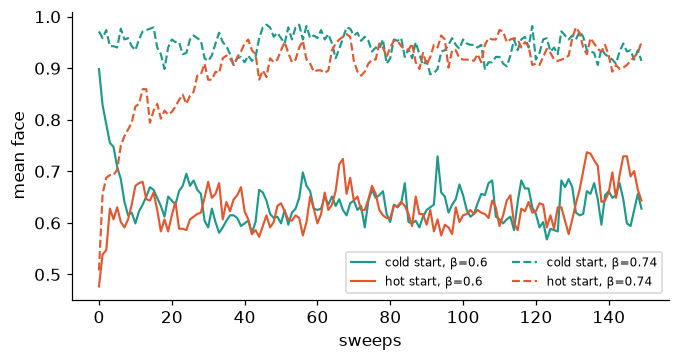

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.4))
for beta, ls in [(0.6, "-"), (0.74, "--")]:
    for start, c in [("cold", viz.TEAL), ("hot", viz.CORAL)]:
        M = GridModel((8, 8, 8), Z2(), beta)
        M.cold_start() if start == "cold" else M.hot_start(rng)
        trace = [(M.sweep(rng), M.mean_face())[1] for _ in range(150)]
        ax.plot(trace, color=c, ls=ls, lw=1.4, label=f"{start} start, β={beta}")
ax.set(xlabel="sweeps", ylabel="mean face")
ax.legend(fontsize=8, ncol=2)
plt.show()

At $\beta=0.6$ the two chains meet within a few sweeps. At $\beta=0.74$ they take much longer: the model is near a point where it changes character (section 4.6), and the chain moves sluggishly there.

**It remembers.** Consecutive samples are correlated, so $n$ chain samples are worth fewer than $n$ independent ones. The **autocorrelation** of the series $f_t$ at lag $k$ is $\rho(k)=\operatorname{corr}(f_t,f_{t+k})$, and the **integrated autocorrelation time** $\tau=\tfrac12+\sum_{k\ge1}\rho(k)$ measures how many sweeps one effective sample costs: $n$ correlated samples carry about as much information as $n/(2\tau)$ independent ones.

In [13]:
def autocorr(x, kmax):
    x = np.asarray(x) - np.mean(x)
    return np.array([np.mean(x[: len(x) - k] * x[k:]) for k in range(kmax)]) / np.var(x)

def tau_int(rho):
    s = 0.5
    for k in range(1, len(rho)):
        if rho[k] < 0.05: break
        s += rho[k]
    return s

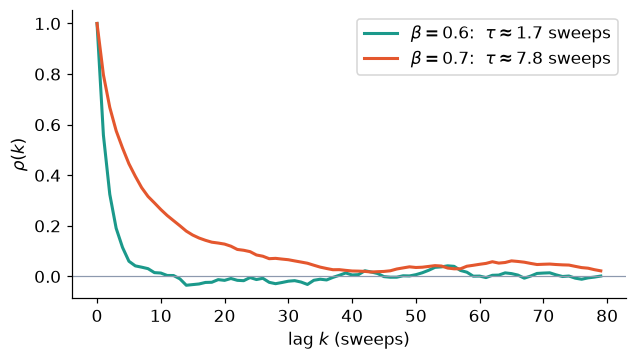

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
series = {}
for beta, c in [(0.6, viz.TEAL), (0.70, viz.CORAL)]:
    M = GridModel((8, 8, 8), Z2(), beta).hot_start(rng); M.sweep(rng, 300)
    series[beta] = np.array([(M.sweep(rng), M.mean_face())[1] for _ in range(8000)])
    rho = autocorr(series[beta], 80)
    ax.plot(rho, color=c, lw=2, label=fr"$\beta={beta}$:  $\tau\approx{tau_int(rho):.1f}$ sweeps")
ax.axhline(0, color=viz.MUTED, lw=0.8)
ax.set(xlabel="lag $k$ (sweeps)", ylabel=r"$\rho(k)$")
ax.legend()
plt.show()

Closer to the special stiffness the memory is longer: about four times longer at $\beta=0.70$ than at $0.6$. It keeps growing as you approach $\beta\approx0.76$. At $\beta=0.74$ even 16,000 sweeps are not enough for the estimates below to settle. This slowdown is a real obstacle in practice, and whole families of cleverer algorithms exist to fight it.

**Error bars that respect memory: binning.** Chop the series into blocks of length $b$ and average each block. Once $b\gg\tau$ the block averages are nearly independent, and the ordinary formula $\text{sd}(\text{blocks})/\sqrt{\#\text{blocks}}$ is honest. Plotting that estimate against $b$, it grows and then levels off at the true error.

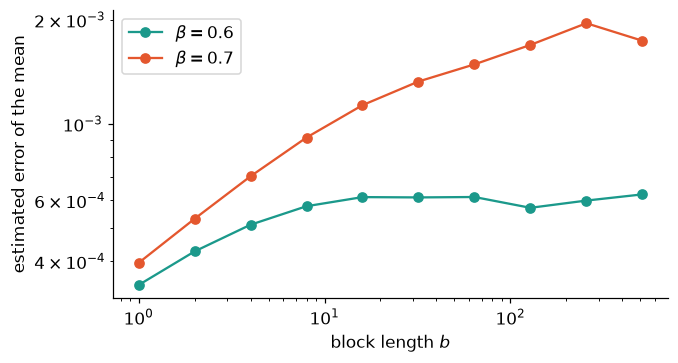

beta=0.6: mean face = 0.6277 ± 0.0006
beta=0.7: mean face = 0.7900 ± 0.0020


In [15]:
def binned_error(x, b):
    m = len(x) // b
    blocks = np.asarray(x[: m * b]).reshape(m, b).mean(axis=1)
    return blocks.std(ddof=1) / np.sqrt(m)

bs = 2 ** np.arange(0, 10)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for beta, c in [(0.6, viz.TEAL), (0.70, viz.CORAL)]:
    ax.plot(bs, [binned_error(series[beta], b) for b in bs], "o-", color=c, label=fr"$\beta={beta}$")
ax.set(xscale="log", yscale="log", xlabel="block length $b$", ylabel="estimated error of the mean")
ax.legend()
plt.show()
for beta in series:
    print(f"beta={beta}: mean face = {series[beta].mean():.4f} ± {binned_error(series[beta], 256):.4f}")

Reading the plateau gives an honest error bar. The naive estimate ($b=1$) understates the error, and the closer you are to the special stiffness, the worse it gets. If the curve never levels off, the honest conclusion is that the run is too short.

> **Recap.** Discard a burn-in (start hot and cold; wait until they agree). Consecutive samples are correlated; the integrated autocorrelation time $\tau$ says how many sweeps one effective sample costs. Binning gives error bars that account for the correlation.

**Check yourself**

1. A run of 10,000 sweeps has $\tau=25$. About how many independent samples is it worth?

<details><summary>Answer</summary>

$10000/(2\cdot25)=200$.

</details>

2. Why does the binned error estimate *grow* with $b$ before it levels off?

<details><summary>Answer</summary>

For small $b$, neighboring blocks are still correlated, so their spread underestimates how much the overall mean can wander. As $b$ passes $\tau$ the blocks decorrelate and the estimate reaches the true error.

</details>

## 4.6 A first experiment, and a puzzle

We now have a tool that works on boards far too large to enumerate. Let's use it to ask a simple question in three settings: **how does the mean face change as we turn the stiffness dial?** We use the coin model on tori of dimension 2, 3 and 4.

To look for surprises we sweep $\beta$ slowly *up*, carrying the chain's labeling from one $\beta$ to the next, and then slowly back *down*. If the model behaves smoothly, the two passes agree.

In [16]:
def scan(dims, betas, equil, measure, rng):
    M = GridModel(dims, Z2(), betas[0]).hot_start(rng)
    out = {}
    for name, bs in [("up", betas), ("down", betas[::-1])]:
        vals = []
        for b in bs:
            M.beta = b
            M.sweep(rng, equil)
            vals.append(np.mean([(M.sweep(rng), M.mean_face())[1] for _ in range(measure)]))
        out[name] = np.array(vals if name == "up" else vals[::-1])
    return out

In [17]:
runs = {2: ((32, 32), np.linspace(0.1, 1.2, 12)),
        3: ((12, 12, 12), np.linspace(0.55, 0.95, 9)),
        4: ((8, 8, 8, 8), np.linspace(0.38, 0.50, 13))}
results = {d: scan(dims, bs, equil=150, measure=40, rng=rng) for d, (dims, bs) in runs.items()}

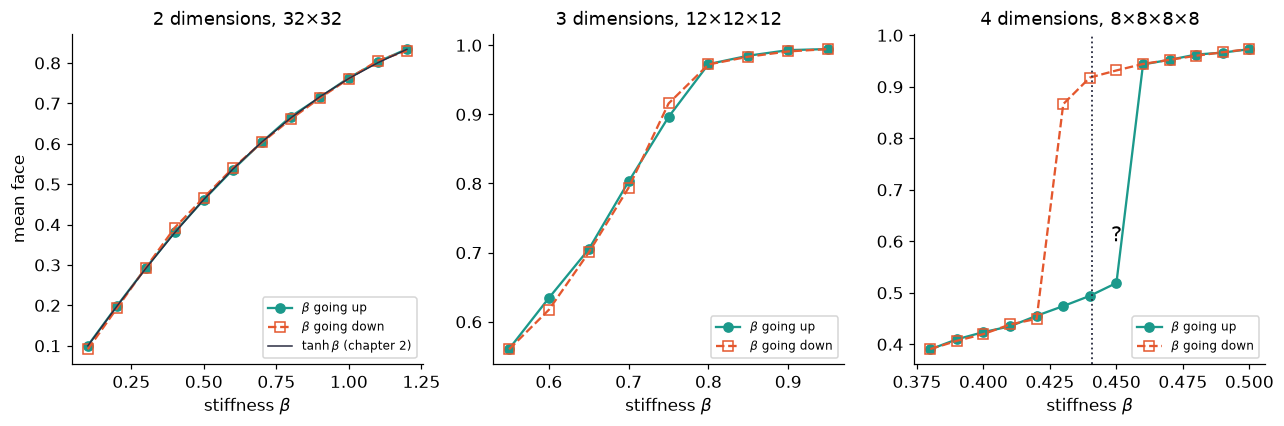

In [18]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.9))
for ax, (d, (dims, bs)) in zip(axs, runs.items()):
    ax.plot(bs, results[d]["up"], "o-", color=viz.TEAL, label=r"$\beta$ going up")
    ax.plot(bs, results[d]["down"], "s--", color=viz.CORAL, mfc="none", label=r"$\beta$ going down")
    ax.set(title=f"{d} dimensions, " + "×".join(map(str, dims)), xlabel=r"stiffness $\beta$")
axs[0].plot(runs[2][1], np.tanh(runs[2][1]), color=viz.INK, lw=1, label=r"$\tanh\beta$ (chapter 2)")
axs[0].set_ylabel("mean face")
axs[2].axvline(0.5 * np.log(1 + np.sqrt(2)), color=viz.INK, ls=":", lw=1.2)
axs[2].text(0.5 * np.log(1 + np.sqrt(2)) + 0.002, 0.6, "  ?", fontsize=14)
for ax in axs: ax.legend(fontsize=8, loc="lower right")
plt.show()

Three very different pictures.

- **2 dimensions:** a smooth curve, exactly $\tanh\beta$, as chapter 2 predicted (faces are nearly independent on a large torus).
- **3 dimensions:** a smooth but steep rise near $\beta\approx0.76$. Up and down agree.
- **4 dimensions:** the two passes **disagree**. Going up, the model stays "rough" until about $\beta\approx0.46$, then jumps; going down, it stays "calm" until about $0.43$, then falls. In between, where the model ends up depends on where it came from. This memory effect is called *hysteresis*, and it is the fingerprint of an abrupt change: two very different typical behaviors, each stable enough that a local chain cannot cross from one to the other.

**The puzzle.** The dotted line is at $\beta^*=\tfrac12\ln(1+\sqrt2)\approx0.4407$, right where the two branches separate. Where would such a number come from? Nothing in our definitions mentions $\sqrt2$. Chapter 9 shows that it can be *derived*, without any simulation: a short exact argument (a Fourier transform on $\mathbb Z_2$) shows that the 4D coin model at stiffness $\beta$ is secretly the same as the 4D coin model at another stiffness $\tilde\beta$, with $\tanh\tilde\beta=e^{-2\beta}$. The only stiffness that is its own partner is $\beta^*$, and that is where the jump must be. The 3D steep rise has a similar exact explanation, with a different partner model.

> **Recap.** The array sampler lets us study big tori. Turning the stiffness up and down reveals that dimension matters: smooth in 2D, steep in 3D, and an abrupt, hysteretic jump in 4D, located at a number we will derive exactly.

**Check yourself**

1. Why do we carry the labeling from one $\beta$ to the next instead of restarting each time?

<details><summary>Answer</summary>

To make memory visible. Restarting would hide which branch the chain was on. (For accurate averages away from the jump, either way works once burn-in is done.)

</details>

2. Would a longer run make the 4D loop disappear?

<details><summary>Answer</summary>

It shrinks slowly, but on a large board crossing between the two behaviors requires the whole board to reorganize, which a local chain essentially never does. The 3D curve, in contrast, already agrees in both directions.

</details>

3. Check the self-partner claim: solve $\tanh\beta=e^{-2\beta}$.

<details><summary>Answer</summary>

Write $t=e^{-2\beta}$. Then $\tanh\beta=\frac{1-t}{1+t}$, so $\frac{1-t}{1+t}=t$, i.e. $t^2+2t-1=0$ and $t=\sqrt2-1$. So $\beta=-\tfrac12\ln(\sqrt2-1)=\tfrac12\ln(1+\sqrt2)\approx0.4407$.

</details>

## Chapter recap

- Averages of invariants can be estimated from random samples, with error $\approx\sigma/\sqrt n$ independent of the number of labelings.
- A Markov chain obeying **detailed balance** samples a model without ever computing $Z$. **Metropolis** proposes and accepts with $\min(1,e^{-\beta\Delta S})$; the **heat bath** draws from the exact conditional distribution.
- **Locality:** one edge's update needs only its **face remainders**, $2(d-1)$ of them on a $d$-dimensional grid. Edges sharing no face can be updated together, which makes array code fast.
- Chains need a **burn-in** and have **memory**: the autocorrelation time $\tau$ sets the cost of an effective sample, and binning gives honest error bars.
- In 4D the coin model shows hysteresis at a stiffness near $0.44$, a number chapter 9 derives exactly.

## Dictionary

| Our term | Other names |
|---|---|
| Markov chain Monte Carlo | MCMC; "Monte Carlo simulation" (physics) |
| Metropolis rule | Metropolis(–Hastings) algorithm |
| heat bath | Gibbs sampling (statistics) |
| face remainder $r_f(e)$, sum $A(e)$ | staple, sum of staples (physics) |
| sweep | one update of every edge; a "lattice sweep" |
| burn-in | thermalization, equilibration |
| cold / hot start | ordered / disordered start |
| slow memory near a special $\beta$ | critical slowing down |
| hysteresis, abrupt jump | first-order phase transition |
| partner stiffness $\tanh\tilde\beta=e^{-2\beta}$ | Kramers–Wannier / Wegner duality; self-dual point |

*History:* the 4D jump was found exactly this way, by Creutz, Jacobs and Rebbi (1979), in one of the first computer studies of these models.

## What's next

So far a model has been a static object: a distribution over whole labelings. Chapter 5 starts Part II, where we cut a board into **layers** and ask how one layer constrains the next. On the simplest boards, chains of vertices, a model *is* a Markov chain in disguise, and one matrix, the transfer matrix, holds all of its secrets.